<a href="https://colab.research.google.com/github/Glads737373/CAPSTONE-FINAL-PROJECT/blob/main/Music_Genre_Classification_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PROJECT** **TITLE**

# Music Genre Classification Analytics

**PROJECT** **GOAL**


*Data Cleaning: Handle missing values, drop duplicate records, and standardize column names and text strings.

*Feature Engineering: Create derived attributes such as duration_minutes, energy_dance_index, and popularity_tier bins.

*Exploratory Data Analysis: Analyze audio feature distributions


*Correlation & Insights: Examine relationships between audio characteristics and investigate performance across popularity tiers.

*Data Visualization: Build static and interactive charts using Matplotlib, Seaborn, and Plotly Express.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [ ]:
df = pd.read_csv('/test.csv')

# **DATASET**

In [ ]:
a = df
a

,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature
0,David Bowie,Space Oddity - 2015 Remaster,73.0,0.310,0.403,NaN,-13.664,1,0.0326,0.07260,0.000093,0.1390,0.466,134.480,318027.000000,4
1,Crimson Sun,Essence of Creation,34.0,0.511,0.955,1.0,-5.059,1,0.1290,0.00040,0.000009,0.2630,0.291,151.937,220413.000000,4
2,P!nk,Raise Your Glass,78.0,0.700,0.709,7.0,-5.006,1,0.0839,0.00480,NaN,0.0289,0.625,122.019,202960.000000,4
3,Shawn Mendes,Wonder,80.0,0.333,0.637,1.0,-4.904,0,0.0581,0.13100,0.000018,0.1490,0.132,139.898,172693.000000,4
4,Backstreet Boys,Helpless When She Smiles - Radio Version,48.0,0.393,0.849,11.0,-4.114,1,0.0459,0.00421,NaN,0.1620,0.222,74.028,4.093117,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7708,Dudu Aharon,◊ë◊ó◊ï◊® ◊®◊í◊ô◊©,28.0,0.816,0.927,7.0,-1.581,1,0.0600,0.26400,NaN,0.0735,0.643,128.019,231680.000000,4
7709,Elephant Tree,Echoes,45.0,0.429,0.599,7.0,-7.236,0,0.0363,0.02540,0.009330,0.3620,0.257,127.446,367879.000000,4
7710,Shankar Mahadevan,Man Mohini,38.0,0.805,0.905,6.0,-7.222,0,0.2750,0.15900,0.000011,0.0590,0.691,135.224,2.453550,4
7711,Talking Heads,Life During Wartime - 2005 Remaster,51.0,0.801,0.930,9.0,-7.365,1,0.0354,0.08060,0.152000,0.0558,0.967,133.255,221320.000000,4


# **DATASET** **INFORMATION**


In [ ]:
a.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7713 entries, 0 to 7712
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Artist Name         7713 non-null   object 
 1   Track Name          7713 non-null   object 
 2   Popularity          7486 non-null   float64
 3   danceability        7713 non-null   float64
 4   energy              7713 non-null   float64
 5   key                 6905 non-null   float64
 6   loudness            7713 non-null   float64
 7   mode                7713 non-null   int64  
 8   speechiness         7713 non-null   float64
 9   acousticness        7713 non-null   float64
 10  instrumentalness    5804 non-null   float64
 11  liveness            7713 non-null   float64
 12  valence             7713 non-null   float64
 13  tempo               7713 non-null   float64
 14  duration_in min/ms  7713 non-null   float64
 15  time_signature      7713 non-null   int64  
dtypes: flo

In [ ]:
print("Number of rows:", a.shape[0])
print("Number of columns:", a.shape[1])
print("Dataset dimensions:", a.shape)

Number of rows: 7713
Number of columns: 16
Dataset dimensions: (7713, 16)


In [ ]:
print ("column names:",a.columns)

column names: Index(['Artist Name', 'Track Name', 'Popularity', 'danceability', 'energy',
       'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo',
       'duration_in min/ms', 'time_signature'],
      dtype='object')


In [ ]:
a.dtypes

,0
Artist Name,object
Track Name,object
Popularity,float64
danceability,float64
energy,float64
key,float64
loudness,float64
mode,int64
speechiness,float64
acousticness,float64


In [ ]:
a.describe()

,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature
count,7486.000000,7713.000000,7713.000000,6905.000000,7713.000000,7713.000000,7713.000000,7713.000000,5804.000000,7713.000000,7713.000000,7713.000000,7.713000e+03,7713.000000
mean,44.968074,0.548110,0.663465,5.924692,-7.840913,0.646311,0.080052,0.241400,0.170052,0.198331,0.489787,122.976657,1.994245e+05,3.918060
std,17.401707,0.164906,0.234822,3.238735,3.982363,0.478145,0.084228,0.308006,0.298011,0.161399,0.237996,29.723547,1.131100e+05,0.369727
min,1.000000,0.000000,0.000020,1.000000,-36.544000,0.000000,0.000000,0.000000,0.000001,0.016900,0.000000,0.000000,6.874500e-01,0.000000
25%,33.000000,0.440000,0.510000,3.000000,-9.527000,0.000000,0.034800,0.004600,0.000092,0.098500,0.306000,99.678000,1.655660e+05,4.000000
50%,44.000000,0.549000,0.699000,6.000000,-6.917000,1.000000,0.047000,0.075600,0.004010,0.131000,0.484000,121.140000,2.088890e+05,4.000000
75%,57.000000,0.661000,0.863000,9.000000,-5.184000,1.000000,0.083300,0.406000,0.165250,0.260000,0.672000,141.984000,2.506940e+05,4.000000
max,100.000000,0.975000,1.000000,11.000000,0.878000,1.000000,0.960000,0.995000,0.987000,0.992000,0.982000,249.438000,1.561133e+06,5.000000


## ***Data*** ***Cleaning***

Handling Missing Values

In [ ]:
a = df
print(a.isnull().sum())

Artist Name              0
Track Name               0
Popularity             227
danceability             0
energy                   0
key                    808
loudness                 0
mode                     0
speechiness              0
acousticness             0
instrumentalness      1909
liveness                 0
valence                  0
tempo                    0
duration_in min/ms       0
time_signature           0
dtype: int64


In [ ]:
df['Popularity'] = df['Popularity'].fillna(df['Popularity'].median())
df['key'] = df['key'].fillna(df['key'].median())
df['instrumentalness'] = df['instrumentalness'].fillna(df['instrumentalness'].median())

In [ ]:
# Identifying object/categorical columns and standardizing them to string type
object_cols = df.select_dtypes(include=['object']).columns

df[object_cols] = df[object_cols].astype('string')
# Additional step: stripping trailing or leading whitespaces
df['Artist Name'] = df['Artist Name'].str.strip()
df['Track Name'] = df['Track Name'].str.strip()

Standardizing column headers and row names

In [ ]:
a.columns = a.columns.str.replace('_', ' ').str.title()

str_cols = a.select_dtypes(include=['object']).columns
for col in str_cols:
    a[col] = a[col].astype(str).str.title()

print("Updated Columns:")
print(a.columns)
print("\nPreview of Data:")
print(a[['Artist Name', 'Track Name']].head())

Updated Columns:
Index(['Artist Name', 'Track Name', 'Popularity', 'Danceability', 'Energy',
       'Key', 'Loudness', 'Mode', 'Speechiness', 'Acousticness',
       'Instrumentalness', 'Liveness', 'Valence', 'Tempo',
       'Duration In Min/Ms', 'Time Signature'],
      dtype='object')

Preview of Data:
       Artist Name                                Track Name
0      David Bowie              Space Oddity - 2015 Remaster
1      Crimson Sun                       Essence of Creation
2             P!nk                          Raise Your Glass
3     Shawn Mendes                                    Wonder
4  Backstreet Boys  Helpless When She Smiles - Radio Version


Duplicate Rows

In [ ]:
print("Duplicate rows:", a.duplicated().sum())

Duplicate rows: 325


In [ ]:
a = a.drop_duplicates().reset_index(drop=True)

print("New shape after removing duplicates:", a.shape)

New shape after removing duplicates: (7388, 16)


In [ ]:
a['Popularity'] = a['Popularity'].fillna(a['Popularity'].median())
a['Key'] = a['Key'].fillna(a['Key'].median())
a['Instrumentalness'] = a['Instrumentalness'].fillna(a['Instrumentalness'].median())

In [ ]:
missing_percentage = (a.isnull().sum() / len(a)) * 100
print(missing_percentage[missing_percentage > 0])

Series([], dtype: float64)


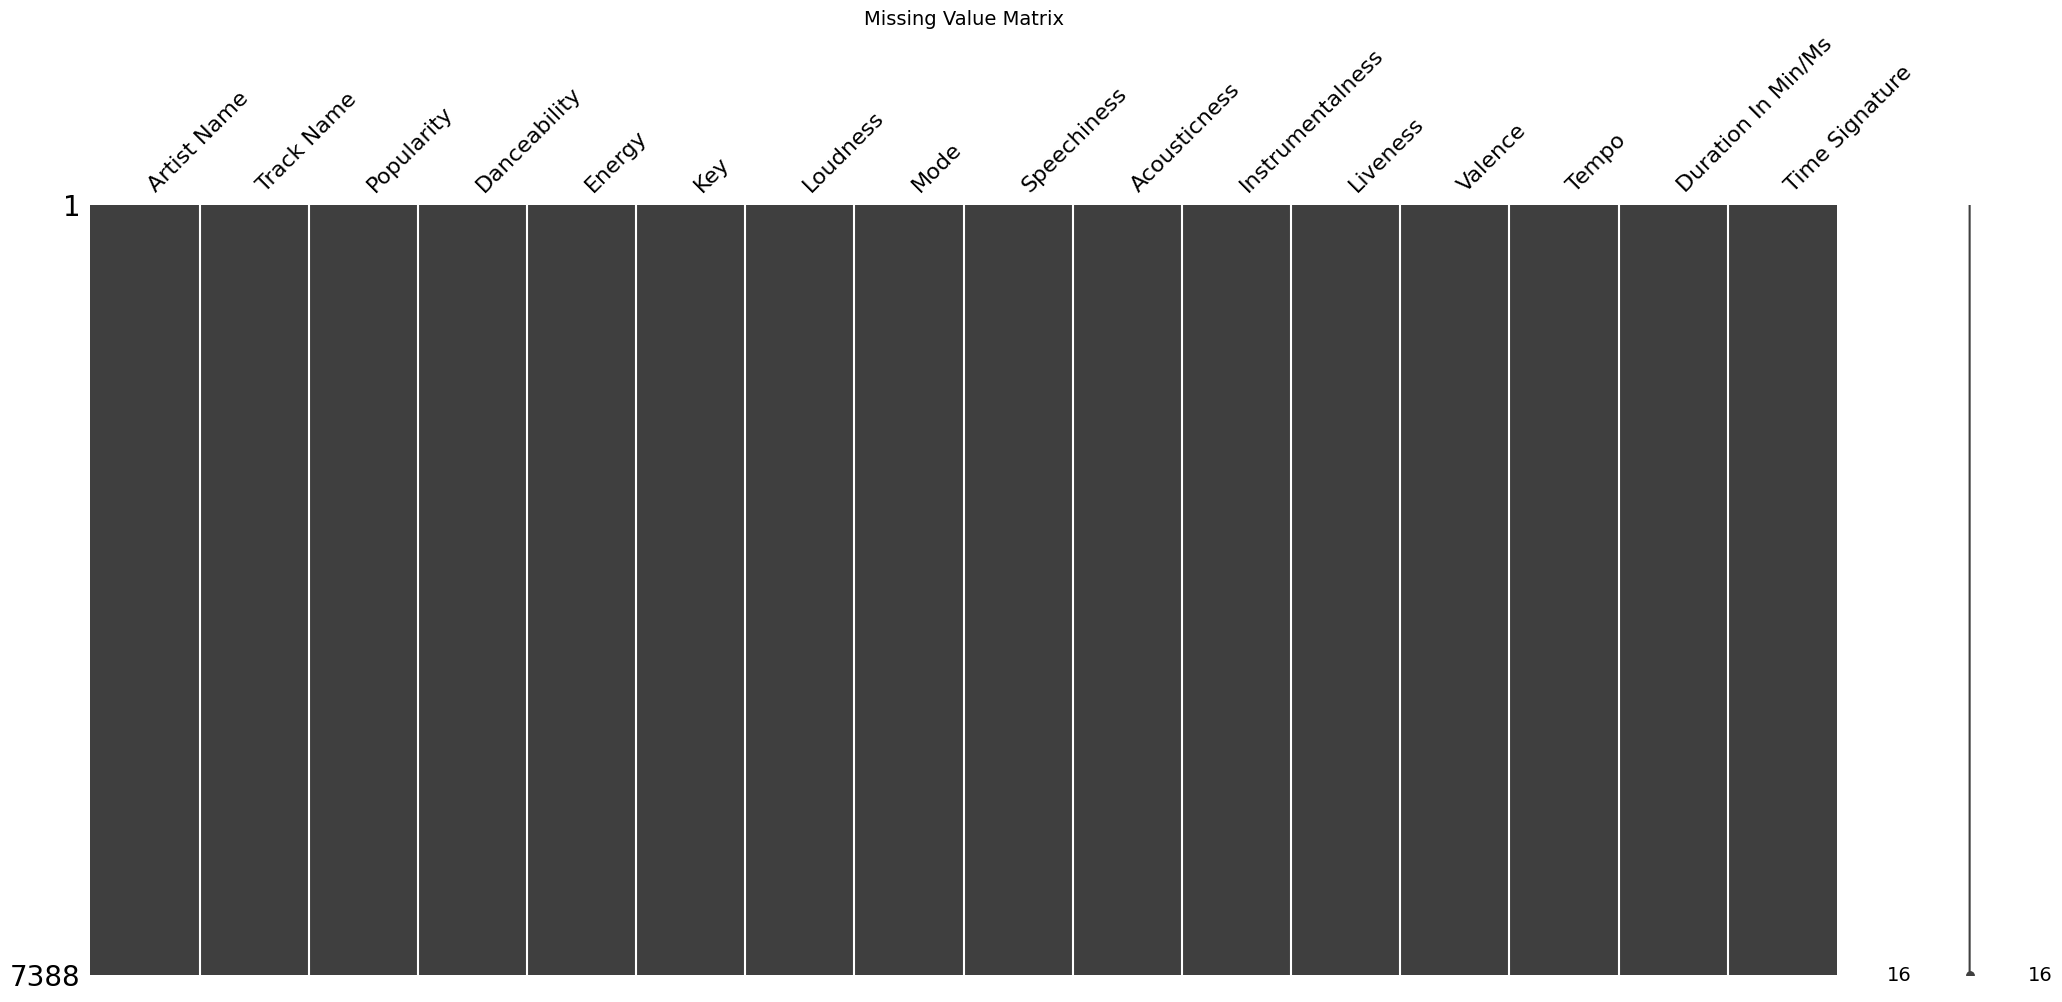

In [ ]:
import missingno as msno
import matplotlib.pyplot as plt

msno.matrix(a)
plt.title('Missing Value Matrix', fontsize=14)
plt.show()

In [ ]:
a['Artist Name'] = a['Artist Name'].fillna('Unknown Artist')

**Correcting track Duration**

Check if the column contains a mix of seconds and milliseconds, or handle outliers by converting or filtering out erroneous values.

In [ ]:
# Check unique or unusual values in duration before conversion
print("Min raw duration value:", a['Duration In Min/Ms'].min())
print("Max raw duration value:", a['Duration In Min/Ms'].max())

# Conditional conversion: If values are greater than 1000, they are in milliseconds. Otherwise, they are already minutes.
a['Duration Minutes'] = a['Duration In Min/Ms'].apply(lambda x: x / 60000 if x > 1000 else x)

# Filter out unrealistic tracks (shorter than 30 seconds or longer than 15 minutes)
a = a[(a['Duration Minutes'] >= 0.5) & (a['Duration Minutes'] <= 15.0)].reset_index(drop=True)
print("New shape after cleaning invalid durations:", a.shape)

Min raw duration value: 0.68745
Max raw duration value: 1561133.0
New shape after cleaning invalid durations: (7374, 17)


**Correcting inconsistent column names**

In [ ]:
# Standardize all columns to lowercase with underscores and strip whitespaces
a.columns = a.columns.str.lower().str.strip().str.replace(' ', '_').str.replace('/', '_')
print("Standardized columns:", a.columns.tolist())

Standardized columns: ['artist_name', 'track_name', 'popularity', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_in_min_ms', 'time_signature', 'duration_minutes']


Checking Duplicate records

In [ ]:
# 1. Check exact row duplicates
print("Exact duplicate rows across all columns:", a.duplicated().sum())

# 2. Check if same track name & artist name appear multiple times (repeated songs)
repeated_tracks = a.duplicated(subset=['artist_name', 'track_name']).sum()
print("Duplicate track name & artist pairs:", repeated_tracks)

# Drop exact duplicates safely
a = a.drop_duplicates().reset_index(drop=True)

Exact duplicate rows across all columns: 0
Duplicate track name & artist pairs: 48


Verifying Popularity Tier Distribution

In [ ]:
# Create Popularity Categories securely with explicit bins
bins = [-1, 33, 66, 100]
labels = ['Low', 'Medium', 'High']
a['popularity_tier'] = pd.cut(a['popularity'], bins=bins, labels=labels, include_lowest=True)

# Verify distribution counts
tier_counts = a['popularity_tier'].value_counts()
print("Track counts per popularity tier:\n", tier_counts)

Track counts per popularity tier:
 popularity_tier
Medium    4676
Low       1852
High       846
Name: count, dtype: int64


Removing leading and trailing spaces

In [ ]:
str_cols = a.select_dtypes(include=['object']).columns
for col in str_cols:
    a[col] = a[col].astype(str).str.strip()

print("Whitespace successfully removed from string columns!")

Whitespace successfully removed from string columns!


In [ ]:
a.columns = a.columns.str.lower().str.replace(' ', '_').str.replace('/', '_')

print(a.columns)

Index(['artist_name', 'track_name', 'popularity', 'danceability', 'energy',
       'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo',
       'duration_in_min_ms', 'time_signature', 'duration_minutes',
       'popularity_tier'],
      dtype='object')


New Columns

In [ ]:
# Convert duration from milliseconds to minutes
a['duration_minutes'] = a['duration_in_min_ms'] / 60000



In [ ]:
# Create an Energy-Danceability interaction feature (captures high-energy dance tracks)
a['energy_dance_index'] = a['energy'] * a['danceability']

In [ ]:
# Create Popularity Categories (Low, Medium, High) for future classification tasks
bins = [0, 33, 66, 100]
labels = ['Low', 'Medium', 'High']
a['popularity_tier'] = pd.cut(a['popularity'], bins=bins, labels=labels, include_lowest=True)

# Verify your new columns
print(a[['track_name', 'duration_minutes', 'energy_dance_index', 'popularity_tier']].head())

                                 track_name  duration_minutes  \
0              Space Oddity - 2015 Remaster          5.300450   
1                       Essence of Creation          3.673550   
2                          Raise Your Glass          3.382667   
3                                    Wonder          2.878217   
4  Helpless When She Smiles - Radio Version          0.000068   

   energy_dance_index popularity_tier  
0            0.124930            High  
1            0.488005          Medium  
2            0.496300            High  
3            0.212121            High  
4            0.333657          Medium  


Number of Outliers

In [ ]:
num_features = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

outlier_counts = {}

for col in num_features:
    Q1 = a[col].quantile(0.25)
    Q3 = a[col].quantile(0.75)
    IQR = Q3 - Q1

    # Define outlier bounds
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Count outliers outside the bounds
    count = a[(a[col] < lower_bound) | (a[col] > upper_bound)].shape[0]
    outlier_counts[col] = count

outlier_df = pd.DataFrame(list(outlier_counts.items()), columns=['Feature', 'Outlier Count'])
print(outlier_df)

            Feature  Outlier Count
0      danceability             34
1            energy              0
2          loudness            321
3       speechiness            863
4      acousticness              0
5  instrumentalness           1508
6          liveness            417
7           valence              0
8             tempo             12


Checking missing values after cleaning


In [ ]:
a.isnull().sum()

,0
artist_name,0
track_name,0
popularity,0
danceability,0
energy,0
key,0
loudness,0
mode,0
speechiness,0
acousticness,0


# EXPLORING DATA ANALYSIS

In [ ]:
a.describe()

,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in_min_ms,time_signature,duration_minutes,energy_dance_index
count,7374.000000,7374.000000,7374.000000,7374.000000,7374.000000,7374.000000,7374.000000,7374.000000,7374.000000,7374.000000,7374.000000,7374.000000,7374.000000,7374.000000,7374.000000,7374.000000
mean,44.713995,0.549090,0.659328,5.928126,-7.894355,0.645104,0.080268,0.247642,0.128609,0.197441,0.488418,122.810122,197522.860715,3.917548,3.292048,0.358149
std,17.114671,0.165098,0.236374,3.063280,4.014833,0.478514,0.083940,0.310452,0.268681,0.161348,0.238928,29.731882,109539.459972,0.369359,1.825658,0.154282
min,1.000000,0.061400,0.000020,1.000000,-36.544000,0.000000,0.022600,0.000000,0.000001,0.016900,0.000000,44.773000,0.687450,1.000000,0.000011,0.000007
25%,33.000000,0.440000,0.504000,4.000000,-9.583000,0.000000,0.034800,0.005040,0.000331,0.098200,0.303250,99.227250,164847.500000,4.000000,2.747458,0.249346
50%,44.000000,0.551000,0.694000,6.000000,-6.958000,1.000000,0.047100,0.083900,0.004010,0.130000,0.481000,120.937500,208662.000000,4.000000,3.477700,0.367545
75%,56.000000,0.663000,0.860000,9.000000,-5.213000,1.000000,0.083700,0.423000,0.044375,0.256000,0.671750,141.917000,250216.500000,4.000000,4.170275,0.469913
max,100.000000,0.975000,1.000000,11.000000,0.878000,1.000000,0.960000,0.995000,0.987000,0.992000,0.982000,249.438000,850867.000000,5.000000,14.181117,0.884198


Outliers with boxplots

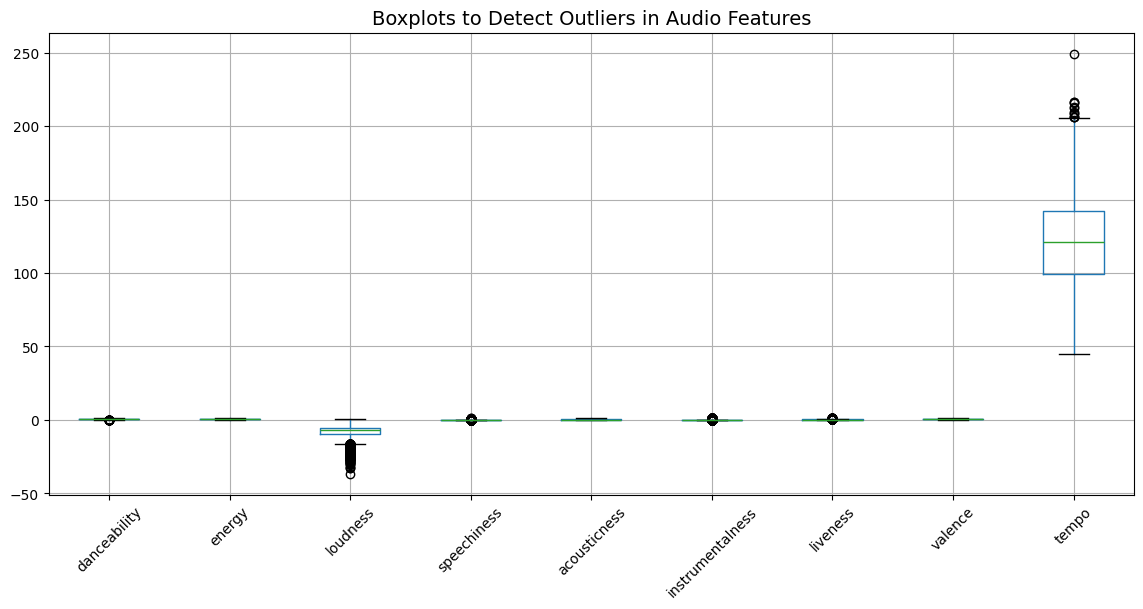

In [ ]:
plt.figure(figsize=(14, 6))
a[num_features].boxplot(rot=45)
plt.title('Boxplots to Detect Outliers in Audio Features', fontsize=14)
plt.show()

Categorical popularity tiers

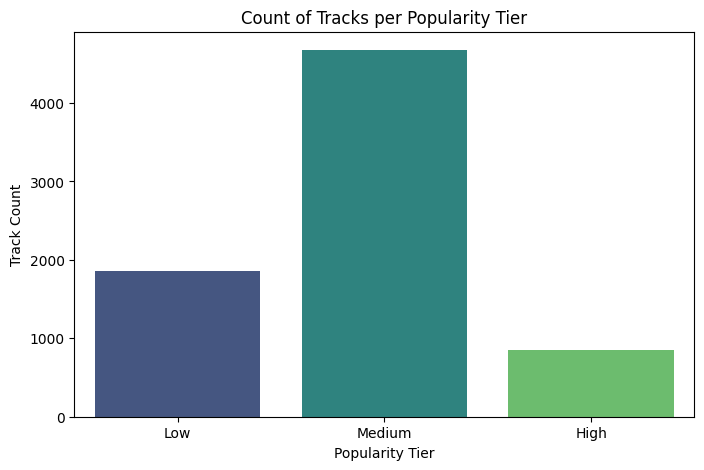

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(x='popularity_tier', data=a, order=['Low', 'Medium', 'High'], palette='viridis', hue='popularity_tier', legend=False)
plt.title('Count of Tracks per Popularity Tier')
plt.xlabel('Popularity Tier')
plt.ylabel('Track Count')
plt.show()

Average Popularity & Feature Summary Table by Tier

In [ ]:
popularity_summary = a.groupby('popularity_tier').agg(
    track_count=('popularity', 'count'),
    mean_popularity=('popularity', 'mean'),
    median_energy=('energy', 'median'),
    median_danceability=('danceability', 'median'),
    median_valence=('valence', 'median')
).reset_index()

print(popularity_summary)

  popularity_tier  track_count  mean_popularity  median_energy  \
0             Low         1852        23.200864         0.6780   
1          Medium         4676        47.894996         0.7030   
2            High          846        74.226950         0.6905   

   median_danceability  median_valence  
0                0.527          0.4690  
1                0.549          0.4735  
2                0.608          0.5395  


/tmp/ipykernel_499/1815908758.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  popularity_summary = a.groupby('popularity_tier').agg(


**Extended AUdio Feature Distributions**



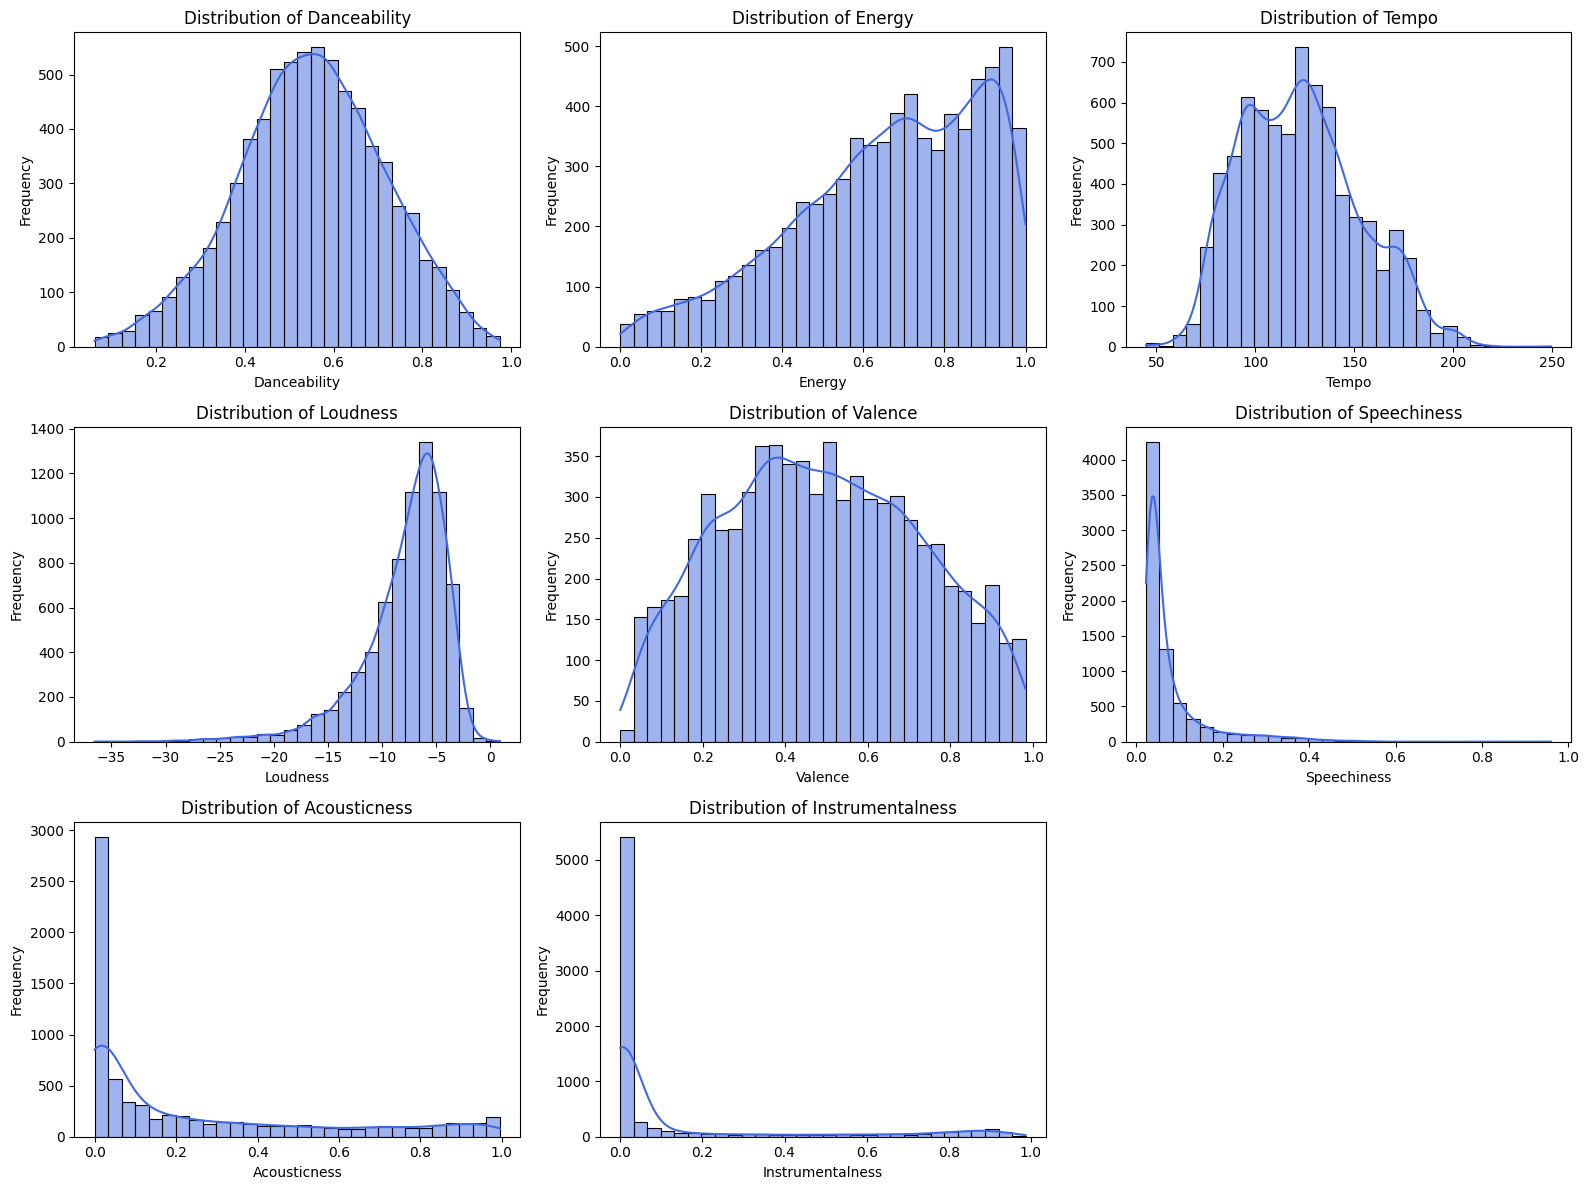

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

num_features = [
    'danceability', 'energy', 'tempo', 'loudness',
    'valence', 'speechiness', 'acousticness', 'instrumentalness'
]

plt.figure(figsize=(16, 12))
for i, col in enumerate(num_features, 1):
    plt.subplot(3, 3, i)
    sns.histplot(a[col], kde=True, bins=30, color='royalblue')
    plt.title(f'Distribution of {col.title()}')
    plt.xlabel(col.title())
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

Track Duration Analysis

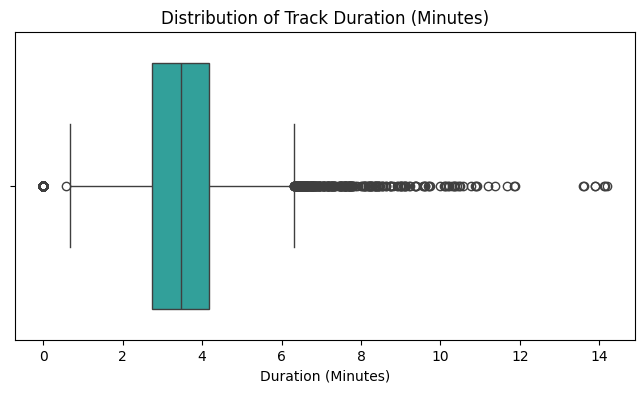

In [ ]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=a['duration_minutes'], color='lightseagreen')
plt.title('Distribution of Track Duration (Minutes)')
plt.xlabel('Duration (Minutes)')
plt.show()

**AUDIO CORRELATION HEATMAP**

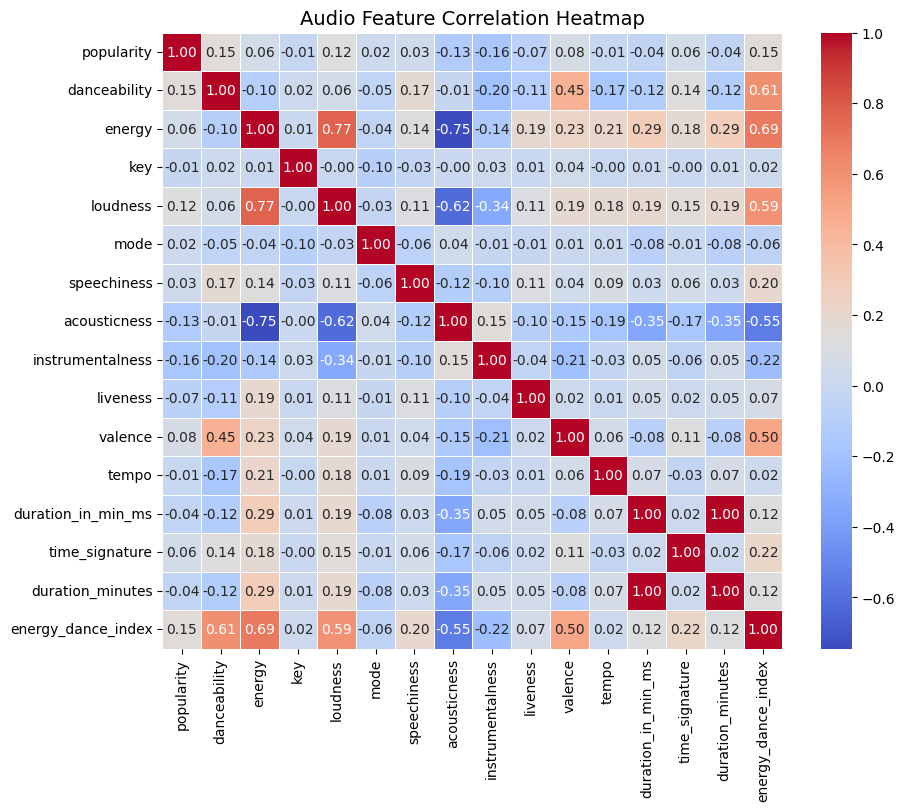

In [ ]:

plt.figure(figsize=(10, 8))
correlation_matrix = a.select_dtypes(include=['float64', 'int64']).corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Audio Feature Correlation Heatmap', fontsize=14)
plt.show()

Multi-Feature Comparison Across Popularity Tiers (Energy, Danceability, Valence)

Median Audio Features by Popularity Tier:
                 energy  danceability  valence
popularity_tier                               
Low              0.6780         0.527   0.4690
Medium           0.7030         0.549   0.4735
High             0.6905         0.608   0.5395


/tmp/ipykernel_499/395815096.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(a.groupby('popularity_tier')[['energy', 'danceability', 'valence']].median())


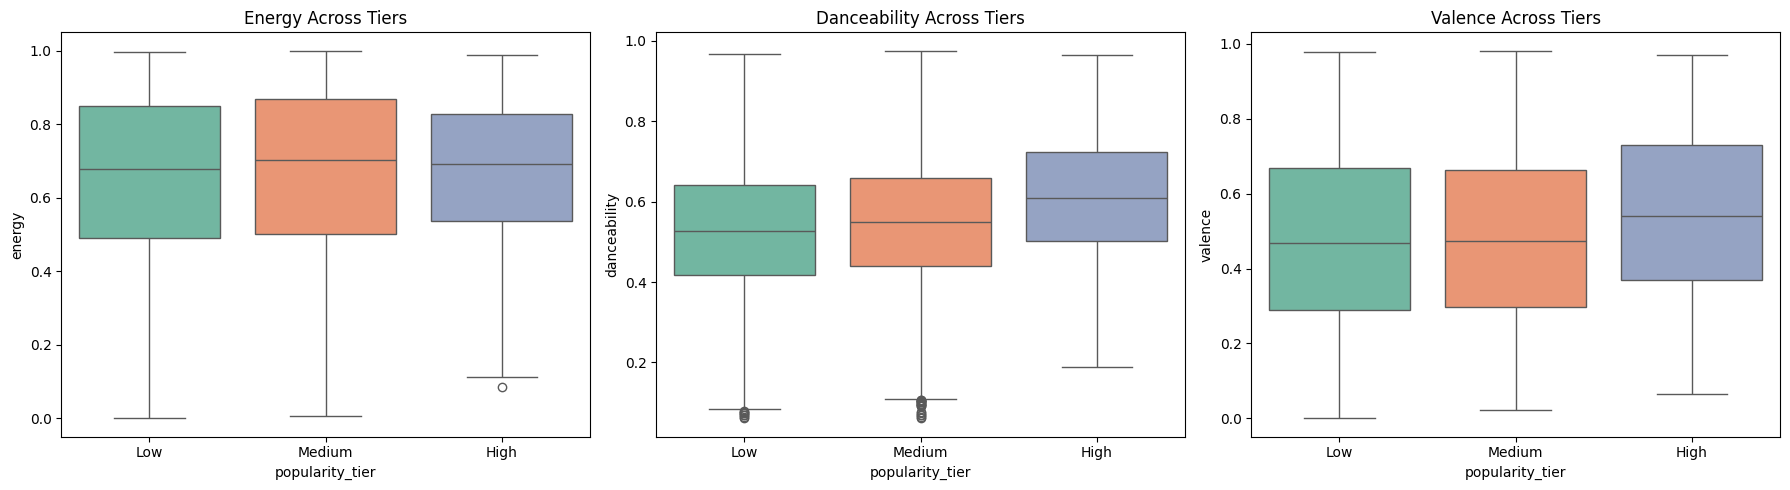

In [ ]:
# Display exact median values for a quantitative breakdown
print("Median Audio Features by Popularity Tier:")
print(a.groupby('popularity_tier')[['energy', 'danceability', 'valence']].median())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(ax=axes[0], data=a, x='popularity_tier', y='energy', order=['Low', 'Medium', 'High'], hue='popularity_tier', palette='Set2', legend=False)
axes[0].set_title('Energy Across Tiers')

sns.boxplot(ax=axes[1], data=a, x='popularity_tier', y='danceability', order=['Low', 'Medium', 'High'], hue='popularity_tier', palette='Set2', legend=False)
axes[1].set_title('Danceability Across Tiers')

sns.boxplot(ax=axes[2], data=a, x='popularity_tier', y='valence', order=['Low', 'Medium', 'High'], hue='popularity_tier', palette='Set2', legend=False)
axes[2].set_title('Valence Across Tiers')

plt.tight_layout()
plt.show()

#TOP 10 MOST FREQUENT ARTIST

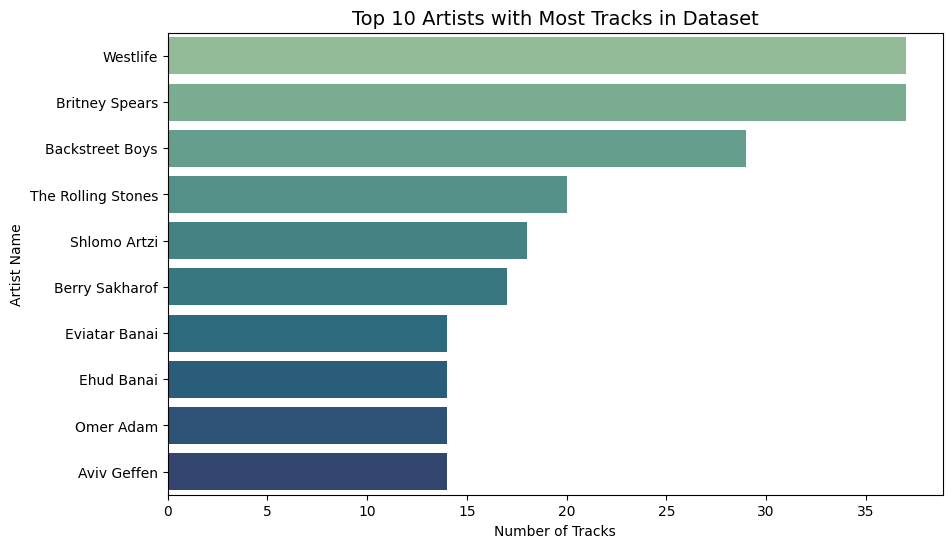

In [ ]:
top_artists = a['artist_name'].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_artists.values, y=top_artists.index, palette='crest', hue=top_artists.index, legend=False)
plt.title('Top 10 Artists with Most Tracks in Dataset', fontsize=14)
plt.xlabel('Number of Tracks')
plt.ylabel('Artist Name')
plt.show()